# Phase 11: Commercial Premium and Scenario Engine

**Business question this phase serves, in full:** *"Segment X has a Loss Ratio above the rest of the
book. Should we reprice it, by how much, and what would that do to retention, new-business conversion
and profitability?"* Phase 7 built the technical premium, Phase 8 found and measured Segment X
(`BonusMalus` 51-80), Phase 9 the retention effect and Phase 10 the conversion effect. This notebook
combines them.

**What this notebook does, in order:**
1. Build a **commercial premium** (technical premium plus an expense loading).
2. Measure Segment X's expected contribution at current pricing.
3. Run the repricing **scenario engine** for Segment X over a range of price changes, and show where
   the engine's own optimum sits.
4. The full breakdown (retained business, new business, contribution) for the indicated correction.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scoring.score_technical_premium import TechnicalPremiumModel, score_technical_premium
from scoring.scenario_engine import run_repricing_scenario, scenario_grid
from src.pricing.commercial_premium import add_commercial_premium, calibrate_breakeven_loading
from src.pricing.portfolio_kpis import add_earned_premium, compute_kpis, DEFAULT_EXPENSE_RATIO
from src.retention.renewal_model import derive_tenure_proxy

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "policy_level_clean.parquet")
tp_model = TechnicalPremiumModel.load(PROJECT_ROOT / "models")
scored = score_technical_premium(df, tp_model)
df = pd.concat([df.reset_index(drop=True), scored.reset_index(drop=True)], axis=1)
df = add_earned_premium(df)
df["tenure_years_proxy"] = derive_tenure_proxy(df["BonusMalus"])

print(f"Portfolio: {len(df):,} policies")

Portfolio: 668,626 policies


## 1. Commercial premium: loading the technical premium for expenses

The technical premium (Phase 7) is the expected claims cost: it reconciles with paid claims on the
training set (Loss Ratio 99.7%) and on the test set (98.3%). The commercial premium adds the expense
loading on top, so that expected claims plus expenses equal the premium:

$$\text{loading} = \frac{\text{expected LR}}{1 - \text{expense ratio}} - 1, \quad \text{expected LR} = 100\%$$

The realized Loss Ratio of the whole book (Phase 8) is not used for this: it is pushed up by a few very
large claims that fell in the validation set (Phase 3 and Phase 8), and a loading calibrated on one
year's large losses would price that volatility into every policy.

In [2]:
EXPECTED_LOSS_RATIO = 1.0  # the technical premium is the expected claims cost (Phase 7)
loading = calibrate_breakeven_loading(EXPECTED_LOSS_RATIO, DEFAULT_EXPENSE_RATIO)
print(f"Expense ratio (assumption, Phase 8): {DEFAULT_EXPENSE_RATIO:.0%}")
print(f"Commercial loading                 : {loading:.2%}")

df = add_commercial_premium(df, loading)

overall_kpis = compute_kpis(df)
print(f"\nRealized book Loss Ratio on the technical premium (all data, Phase 8): {overall_kpis['loss_ratio']:.1%}")

Expense ratio (assumption, Phase 8): 27%
Commercial loading                 : 36.99%



Realized book Loss Ratio on the technical premium (all data, Phase 8): 112.7%

**Reading:** with a 27% expense ratio, the commercial premium is the technical premium plus 37%.
At this level the book breaks even in expectation; the realized ratio above differs because of where
a few large claims landed, not because of a pricing gap (Phase 8 Section 3).

## 2. Segment X at commercial pricing, before any correction

At the book level the commercial premium breaks even in expectation (checked below: contribution of
zero for the whole book at 0% price change). Segment X costs more than its technical premium predicts
(Phase 8: cost relativity 1.17, measured out of sample), so it should show a negative margin at the
same loading.

In [3]:
from src.pricing.segment_x import in_segment_x, load_segment_x

segment_x = load_segment_x(PROJECT_ROOT)  # written by Phase 8: loaded, not retyped
seg = df[in_segment_x(df, segment_x)].copy()

# One cost basis for the loading and the scenario engine: expected cost = technical premium x factor.
# Book factor = 1 (the loading assumes the technical premium is the expected cost); segment factor =
# the segment's out-of-sample cost relativity measured in Phase 8.
book_cost_factor = EXPECTED_LOSS_RATIO
seg_cost_factor = book_cost_factor * segment_x["cost_relativity"]

book_check = run_repricing_scenario(df, price_change_pct=0.0, cost_factor=book_cost_factor)
print(f"Check, whole book at current pricing, contribution: EUR {book_check['total_contribution']:,.0f} (should be 0)")

avg_commercial = seg["commercial_premium"].mean()
avg_cost = (seg["technical_premium"] * seg_cost_factor).mean()
avg_margin_per_policy = avg_commercial * (1 - DEFAULT_EXPENSE_RATIO) - avg_cost

print()
print(f"Segment X ({segment_x['label']}): {len(seg):,} policies ({seg['Exposure'].sum() / df['Exposure'].sum():.1%} of portfolio exposure)")
print(f"Expected cost / technical premium, segment : {seg_cost_factor:.3f}")
print(f"Average commercial premium : EUR {avg_commercial:,.2f}")
print(f"Average expected cost      : EUR {avg_cost:,.2f}")
print(f"Average margin per policy after expenses: EUR {avg_margin_per_policy:,.2f}")

baseline_scenario = run_repricing_scenario(seg, price_change_pct=0.0, cost_factor=seg_cost_factor)
print()
print(f"Segment X expected annual contribution at current pricing: EUR {baseline_scenario['total_contribution']:,.0f}")

Check, whole book at current pricing, contribution: EUR -0 (should be 0)

Segment X (BonusMalus 51-80): 211,105 policies (28.3% of portfolio exposure)
Expected cost / technical premium, segment : 1.166
Average commercial premium : EUR 216.21
Average expected cost      : EUR 184.06
Average margin per policy after expenses: EUR -26.23

Segment X expected annual contribution at current pricing: EUR -5,702,990


**Reading:** the whole book breaks even, as designed, while Segment X's average margin after
expenses is **negative** (about EUR -26 per policy), about EUR -5.7M of expected annual contribution
on the segment.

## 3. The scenario engine: repricing Segment X over a range of price changes

Evaluated from -10% to +30%, the range the retention and conversion assumptions were set for (Phases
9-10 validated their curves from -20% to +30%).

In [4]:
price_changes = list(np.linspace(-0.10, 0.30, 25))
grid = scenario_grid(seg, price_changes, cost_factor=seg_cost_factor)
grid[["price_change_pct", "renewal_rate", "conversion_rate", "total_written_premium", "total_contribution"]]

,price_change_pct,renewal_rate,conversion_rate,total_written_premium,total_contribution
0,-0.1000,0.9020,0.2433,"47,081,171.2118","-10,164,878.4613"
1,-0.0833,0.8986,0.2254,"47,056,241.0457","-9,350,213.2469"
2,-0.0667,0.8951,0.2084,"47,034,461.4409","-8,565,866.9607"
3,-0.0500,0.8915,0.1924,"47,017,760.2359","-7,810,443.0683"
4,-0.0333,0.8878,0.1773,"47,007,651.9228","-7,082,482.0137"
5,-0.0167,0.8840,0.1632,"47,005,254.1943","-6,380,494.3778"
6,0.0000,0.8800,0.1500,"47,011,311.5351","-5,702,990.3677"
7,0.0167,0.8759,0.1377,"47,026,224.0363","-5,048,505.2716"
8,0.0333,0.8717,0.1262,"47,050,079.7275","-4,415,620.7453"
9,0.0500,0.8674,0.1156,"47,082,688.9065","-3,802,981.9854"


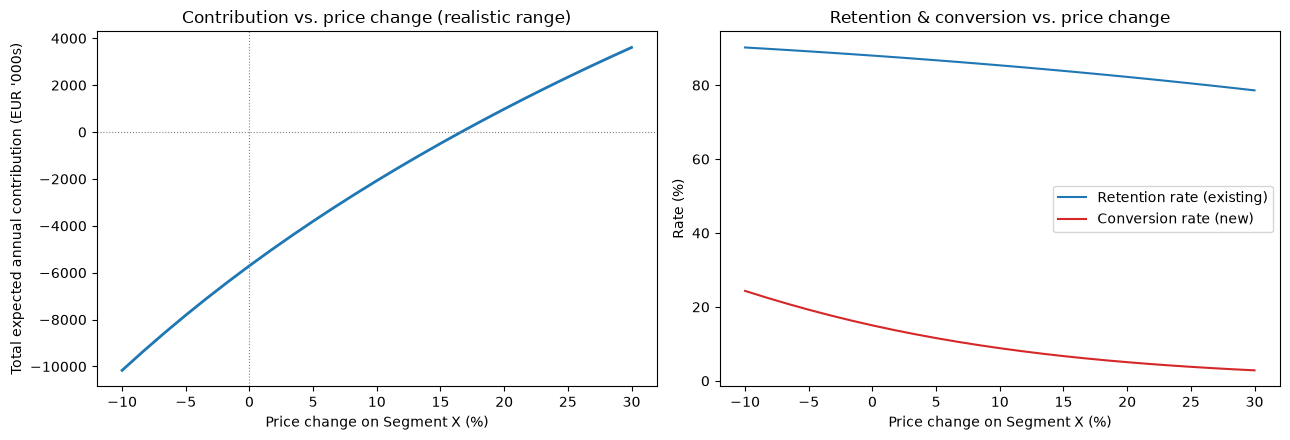

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(grid["price_change_pct"] * 100, grid["total_contribution"] / 1000, color="#1f77b4", linewidth=2)
axes[0].axhline(0, color="gray", linewidth=0.8, linestyle=":")
axes[0].axvline(0, color="gray", linewidth=0.8, linestyle=":")
axes[0].set_xlabel("Price change on Segment X (%)")
axes[0].set_ylabel("Total expected annual contribution (EUR '000s)")
axes[0].set_title("Contribution vs. price change (realistic range)")

axes[1].plot(grid["price_change_pct"] * 100, grid["renewal_rate"] * 100, label="Retention rate (existing)", color="#1f77b4")
axes[1].plot(grid["price_change_pct"] * 100, grid["conversion_rate"] * 100, label="Conversion rate (new)", color="#d62728")
axes[1].set_xlabel("Price change on Segment X (%)")
axes[1].set_ylabel("Rate (%)")
axes[1].set_title("Retention & conversion vs. price change")
axes[1].legend()

fig.tight_layout()
plt.show()

**Reading:** over this whole range, expected contribution **improves steadily** with a larger price
correction; there is no peak inside the range. The next section explains why.

## 4. Why there is no peak in this range, and where the engine's own optimum sits

The retention and conversion curves (Phases 9-10) decay like logistic functions of the price change,
while the premium per policy grows linearly, so total contribution must peak somewhere. With the
elasticities used here, that peak lies far beyond any single repricing action.

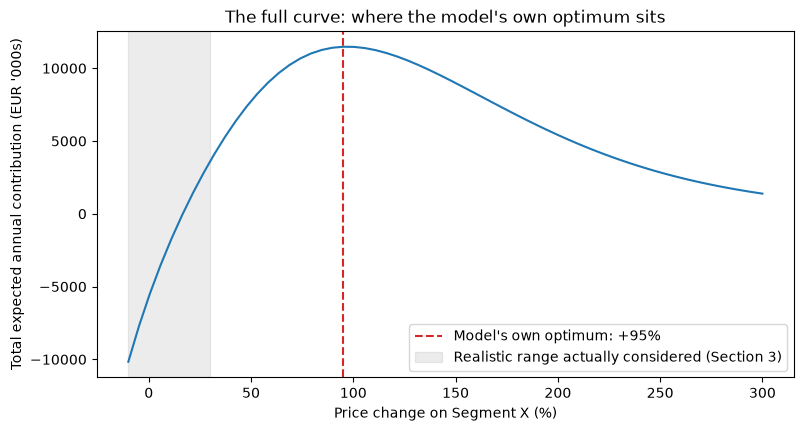

The model's own mathematical optimum: +95% price change
Outside the range the retention and conversion assumptions were set for (Phase 9/10): not a recommendation.


In [6]:
wide_price_changes = list(np.linspace(-0.10, 3.0, 60))
wide_grid = scenario_grid(seg, wide_price_changes, cost_factor=seg_cost_factor)
peak_idx = wide_grid["total_contribution"].idxmax()
peak_row = wide_grid.loc[peak_idx]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(wide_grid["price_change_pct"] * 100, wide_grid["total_contribution"] / 1000, color="#1f77b4")
ax.axvline(peak_row["price_change_pct"] * 100, color="#d62728", linestyle="--", label=f"Model's own optimum: +{peak_row['price_change_pct']:.0%}")
ax.axvspan(-10, 30, color="gray", alpha=0.15, label="Realistic range actually considered (Section 3)")
ax.set_xlabel("Price change on Segment X (%)")
ax.set_ylabel("Total expected annual contribution (EUR '000s)")
ax.set_title("The full curve: where the model's own optimum sits")
ax.legend()
plt.show()

print(f"The model's own mathematical optimum: +{peak_row['price_change_pct']:.0%} price change")
print("Outside the range the retention and conversion assumptions were set for (Phase 9/10): not a recommendation.")

**What this means in practice:** the engine's optimum (+95%) is far outside the range its retention
and conversion assumptions were set for, and no insurer would move a segment's price by that much in
one step (competitive position, regulation, customer relations). It is shown to describe the engine's
behavior, not as a recommendation. Within the realistic range, a correction that removes the measured
gap stays net positive in expectation.

## 5. The indicated correction

The indicated correction is **+17%**: the segment's out-of-sample cost relativity measured in Phase 8
(1.17), loaded from `reports/figures/segment_x.json`. It brings the segment's price in line with its
expected cost, rather than chasing the engine's optimum.

In [7]:
price_change = segment_x["indicated_price_change"]
recommended = run_repricing_scenario(seg, price_change_pct=price_change, cost_factor=seg_cost_factor)
baseline = run_repricing_scenario(seg, price_change_pct=0.0, cost_factor=seg_cost_factor)

label = f"{price_change:+.0%} correction"
print(f"Segment X: {segment_x['label']}")
print(f"{'Metric':<46}{'Current pricing':>18}{label:>18}")
print(f"{'Renewal rate':<46}{baseline['renewal_rate']:>17.1%} {recommended['renewal_rate']:>17.1%}")
print(f"{'Conversion rate':<46}{baseline['conversion_rate']:>17.1%} {recommended['conversion_rate']:>17.1%}")
print(f"{'Expected renewed policies':<46}{baseline['expected_renewals']:>18,.0f}{recommended['expected_renewals']:>18,.0f}")
print(f"{'Expected new policies':<46}{baseline['expected_new_policies']:>18,.0f}{recommended['expected_new_policies']:>18,.0f}")
print(f"{'Segment written premium (EUR)':<46}{baseline['total_written_premium']:>18,.0f}{recommended['total_written_premium']:>18,.0f}")
print(f"{'Segment expected annual contribution (EUR)':<46}{baseline['total_contribution']:>18,.0f}{recommended['total_contribution']:>18,.0f}")

contribution_improvement = recommended["total_contribution"] - baseline["total_contribution"]
print()
print(f"Projected change in the segment's annual contribution: EUR {contribution_improvement:,.0f}")

Segment X: BonusMalus 51-80
Metric                                           Current pricing   +17% correction
Renewal rate                                              88.0%             83.2%
Conversion rate                                           15.0%              6.0%
Expected renewed policies                                185,772           175,697
Expected new policies                                     31,666            12,630
Segment written premium (EUR)                         47,011,312        47,512,215
Segment expected annual contribution (EUR)            -5,702,990           113,257

Projected change in the segment's annual contribution: EUR 5,816,247


**Answer to the business question:** yes, Segment X (`BonusMalus` 51-80, 28.3% of exposure) should
be repriced. Under this project's assumptions, the +17% correction loses about 4.8% of existing
policies and cuts new-business conversion from 15.0% to 6.0%, and brings the segment's expected annual
contribution from about EUR -5.7M to about breakeven.

Two caveats frame that number. The retention and conversion effects come from documented simulators
(Phases 9-10), not from observed behavior; and the new-business volume assumes as many quotes as
current policies (see `scoring/scenario_engine.py`). In practice the correction is the `BonusMalus`
relativity for the 51-80 band; the next tariff revision should model `BonusMalus` in bands (Phase 8
mechanism check), and the change should be monitored with a test-and-learn cell so the retention and
conversion assumptions can be recalibrated on real experience.

## 6. Save the scenario results

In [8]:
reports_dir = PROJECT_ROOT / "reports" / "figures"
reports_dir.mkdir(parents=True, exist_ok=True)
grid.to_csv(reports_dir / "segment_x_repricing_scenario_grid.csv", index=False)
print(f"Saved: {(reports_dir / 'segment_x_repricing_scenario_grid.csv').relative_to(PROJECT_ROOT).as_posix()}")

Saved: reports/figures/segment_x_repricing_scenario_grid.csv


## Phase 11 summary

| Check | Result |
|---|---|
| Commercial loading | 37.0%: expense ratio of 27% on a technical premium equal to expected cost; whole-book contribution of zero at 0% change, checked |
| Segment X at current pricing | Average margin after expenses about EUR -26 per policy; expected contribution about EUR -5.7M a year |
| Scenario engine, range -10% to +30% | Contribution improves steadily; no peak inside the range |
| Engine optimum | +95%, outside the range the retention and conversion assumptions cover: not a recommendation |
| **Indicated correction** | **+17% on `BonusMalus` 51-80**, equal to the measured cost relativity; brings the segment to about breakeven (change of about EUR +5.8M a year) |
| Caveats | Simulated retention and conversion; quote volume assumption; to be monitored with a test-and-learn cell |

**Output:** [`reports/figures/segment_x_repricing_scenario_grid.csv`](../reports/figures/segment_x_repricing_scenario_grid.csv),
ready for **Phase 12: Streamlit app**.